# BrushCue Example: Sootline Mono

<a href="https://colab.research.google.com/github/ditotechnologies/brushcue/blob/main/examples/sootline_mono.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

You can use this tool online at https://www.brushcue.com/tools/sootline-mono

In [ ]:
!pip install brushcue

[wgpu] using backend Vulkan — adapter 'NVIDIA GeForce RTX 5070' (DiscreteGpu), driver 'NVIDIA'


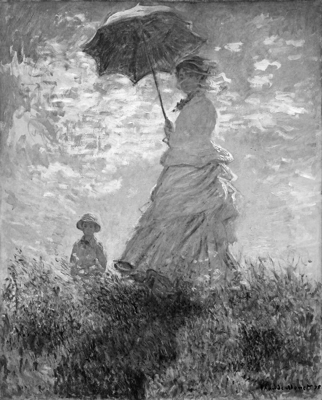

In [1]:
import io
from PIL import Image

import brushcue as bc

strength = 1.0
input_image = bc.Composition.monet_women_with_parasol()
bounds = input_image.bounds()
grained = input_image.film_grain(1.51, 150.0, 0.5, 51.0, 0.3, 300.0, 0.2)
contrasted = grained.grayscale().l_curve(bc.Curve.s_curve(0.5, 1.6, 1.0, 1.0))
filtered = contrasted.vignette(
    bc.Vector2f.from_components((bounds.width() / 2.0), (bounds.height() / 2.0)),
    (bounds.width() / 2.0),
    (bounds.height() / 2.0),
    350.0,
    0.22,
).crop(bounds)
graph = filtered.opacity_scales(strength).blend_alpha(input_image).crop(bounds)

ctx = bc.Context()
composition = graph.execute(ctx)
data_bytes = composition.to_image_bytes(ctx)
img = Image.open(io.BytesIO(data_bytes))
img.thumbnail((400, 400))  # Remove this line for full resolution
img
